In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv('Bankruptcy_prevention_Dataset.csv',sep=';')

In [3]:
df.head()

,industrial_risk,management_risk,financial_flexibility,credibility,competitiveness,operating_risk,class
0,0.5,1.0,0.0,0.0,0.0,0.5,bankruptcy
1,0.0,1.0,0.0,0.0,0.0,1.0,bankruptcy
2,1.0,0.0,0.0,0.0,0.0,1.0,bankruptcy
3,0.5,0.0,0.0,0.5,0.0,1.0,bankruptcy
4,1.0,1.0,0.0,0.0,0.0,1.0,bankruptcy


In [4]:
df.shape

(250, 7)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   industrial_risk         250 non-null    float64
 1    management_risk        250 non-null    float64
 2    financial_flexibility  250 non-null    float64
 3    credibility            250 non-null    float64
 4    competitiveness        250 non-null    float64
 5    operating_risk         250 non-null    float64
 6    class                  250 non-null    object 
dtypes: float64(6), object(1)
memory usage: 13.8+ KB


In [6]:
df.columns=df.columns.str.strip()

In [7]:
df.isnull().sum()

industrial_risk          0
management_risk          0
financial_flexibility    0
credibility              0
competitiveness          0
operating_risk           0
class                    0
dtype: int64

In [8]:
df['class'].value_counts()

class
non-bankruptcy    143
bankruptcy        107
Name: count, dtype: int64

In [9]:
df.duplicated().sum()

np.int64(147)

In [10]:
df[df.duplicated()]

,industrial_risk,management_risk,financial_flexibility,credibility,competitiveness,operating_risk,class
11,0.0,1.0,0.0,0.0,0.0,1.0,bankruptcy
13,1.0,1.0,0.0,0.0,0.0,1.0,bankruptcy
15,0.5,1.0,0.0,0.0,0.0,0.5,bankruptcy
16,0.5,1.0,0.0,0.0,0.0,0.5,bankruptcy
18,0.5,1.0,0.0,0.0,0.0,1.0,bankruptcy
...,...,...,...,...,...,...,...
245,0.0,1.0,1.0,1.0,1.0,1.0,non-bankruptcy
246,1.0,1.0,0.5,1.0,1.0,0.0,non-bankruptcy
247,0.0,1.0,1.0,0.5,0.5,0.0,non-bankruptcy
248,1.0,0.0,0.5,1.0,0.5,0.0,non-bankruptcy


In [11]:
df.describe()

,industrial_risk,management_risk,financial_flexibility,credibility,competitiveness,operating_risk
count,250.000000,250.000000,250.000000,250.000000,250.000000,250.000000
mean,0.518000,0.614000,0.376000,0.470000,0.476000,0.570000
std,0.411526,0.410705,0.401583,0.415682,0.440682,0.434575
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.500000,0.000000,0.000000,0.000000,0.000000
50%,0.500000,0.500000,0.500000,0.500000,0.500000,0.500000
75%,1.000000,1.000000,0.500000,1.000000,1.000000,1.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


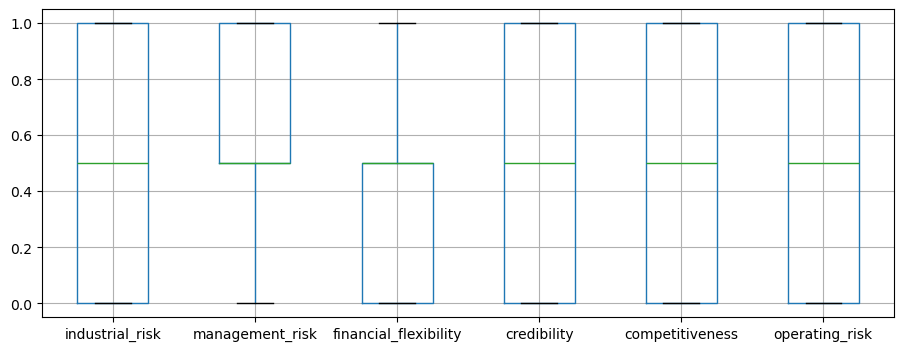

In [12]:
plt.figure(figsize=(11,4))
df.boxplot()
plt.show()

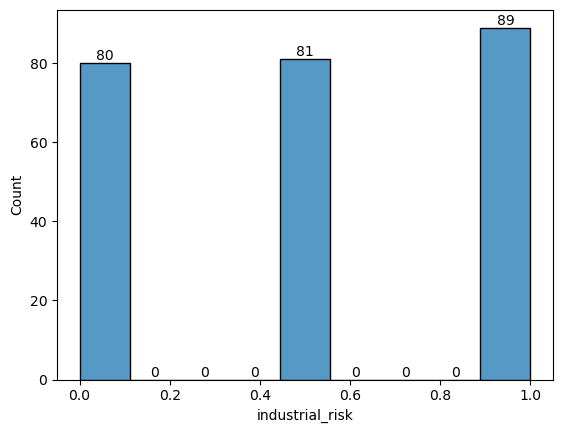

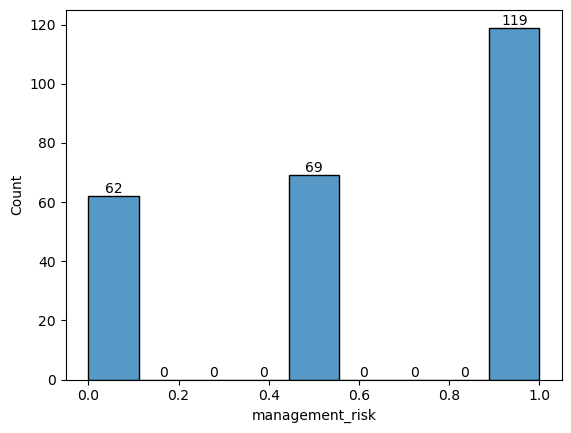

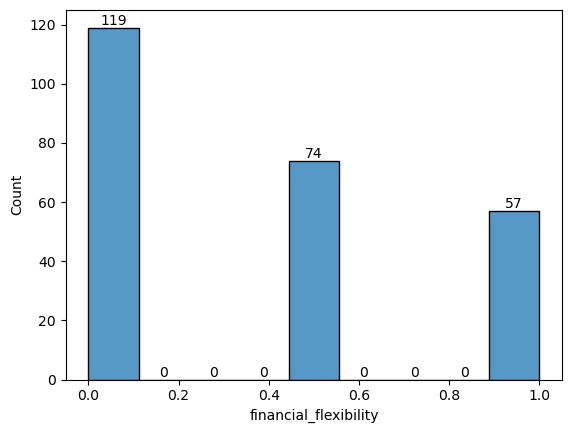

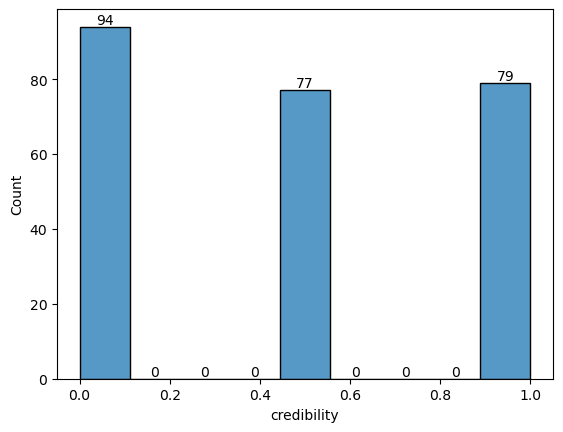

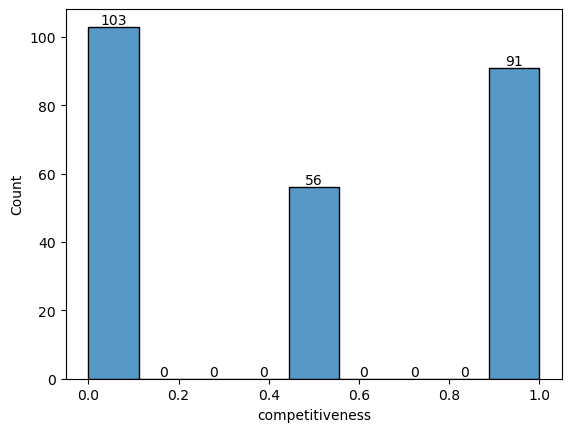

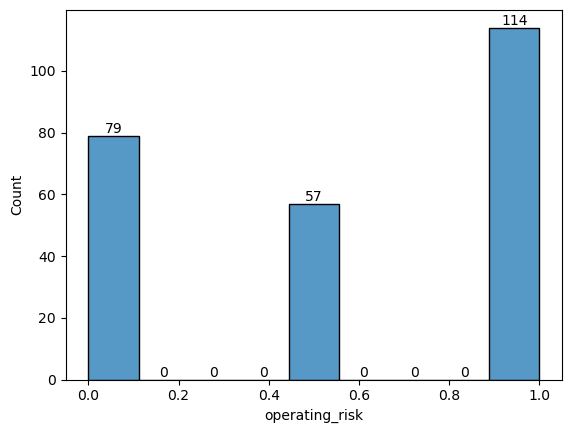

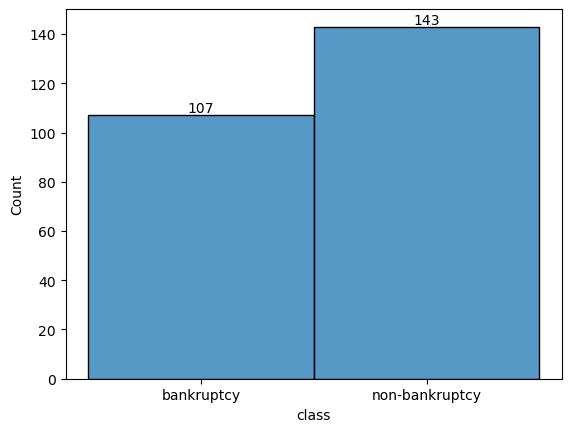

In [13]:
for i in df.columns:
    ax=sns.histplot(df,x=i)
    for c in ax.containers:
        ax.bar_label(c)
    plt.show()

In [14]:
df['class']=df['class'].map({'non-bankruptcy':0, 'bankruptcy':1})

In [15]:
df.loc[[3,140]]

,industrial_risk,management_risk,financial_flexibility,credibility,competitiveness,operating_risk,class
3,0.5,0.0,0.0,0.5,0.0,1.0,1
140,1.0,0.0,0.5,1.0,0.5,0.0,0


In [16]:
cor=df.corr()
cor

,industrial_risk,management_risk,financial_flexibility,credibility,competitiveness,operating_risk,class
industrial_risk,1.000000,0.255127,-0.162624,-0.014438,-0.257814,0.144507,0.227823
management_risk,0.255127,1.000000,-0.254845,-0.303341,-0.306568,0.213874,0.370838
financial_flexibility,-0.162624,-0.254845,1.000000,0.524951,0.686612,-0.116903,-0.751020
credibility,-0.014438,-0.303341,0.524951,1.000000,0.675689,-0.288458,-0.755909
competitiveness,-0.257814,-0.306568,0.686612,0.675689,1.000000,-0.211383,-0.899452
operating_risk,0.144507,0.213874,-0.116903,-0.288458,-0.211383,1.000000,0.279786
class,0.227823,0.370838,-0.751020,-0.755909,-0.899452,0.279786,1.000000


<Axes: >

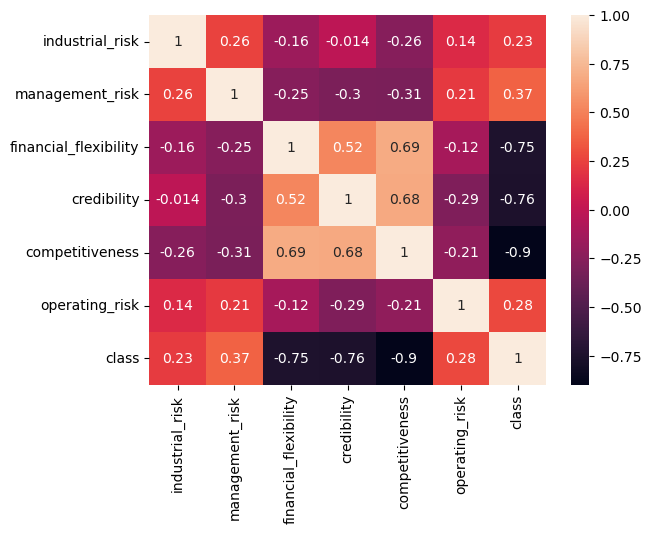

In [17]:
sns.heatmap(cor,annot=True)

**MODEL BUILDING**

In [18]:
features=df.drop(columns=['class'])
target=df['class']

In [19]:
features.head()

,industrial_risk,management_risk,financial_flexibility,credibility,competitiveness,operating_risk
0,0.5,1.0,0.0,0.0,0.0,0.5
1,0.0,1.0,0.0,0.0,0.0,1.0
2,1.0,0.0,0.0,0.0,0.0,1.0
3,0.5,0.0,0.0,0.5,0.0,1.0
4,1.0,1.0,0.0,0.0,0.0,1.0


In [20]:
from sklearn.feature_selection import f_classif

In [21]:
fcls=f_classif(features,target)

In [22]:
pd.DataFrame(fcls[0],index=features.columns,columns=['score']).sort_values(by='score',ascending=False)

,score
competitiveness,1050.520973
credibility,330.625672
financial_flexibility,320.846947
management_risk,39.543195
operating_risk,21.062291
industrial_risk,13.576657


In [23]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [24]:
vif=pd.DataFrame()

In [25]:
vif['features']=features.columns

In [26]:
features_with_constant=features.copy()
features_with_constant['Intercept']=1

In [27]:
features_with_constant

,industrial_risk,management_risk,financial_flexibility,credibility,competitiveness,operating_risk,Intercept
0,0.5,1.0,0.0,0.0,0.0,0.5,1
1,0.0,1.0,0.0,0.0,0.0,1.0,1
2,1.0,0.0,0.0,0.0,0.0,1.0,1
3,0.5,0.0,0.0,0.5,0.0,1.0,1
4,1.0,1.0,0.0,0.0,0.0,1.0,1
...,...,...,...,...,...,...,...
245,0.0,1.0,1.0,1.0,1.0,1.0,1
246,1.0,1.0,0.5,1.0,1.0,0.0,1
247,0.0,1.0,1.0,0.5,0.5,0.0,1
248,1.0,0.0,0.5,1.0,0.5,0.0,1


In [28]:
vif['VIF']=[
    variance_inflation_factor(features_with_constant.values,i)
    for i in range(len(features.columns))
]

In [29]:
vif=vif.sort_values(by="VIF",ascending=False)
print(vif)

                features       VIF
4        competitiveness  2.788219
3            credibility  2.128103
2  financial_flexibility  1.931439
0        industrial_risk  1.208550
1        management_risk  1.205396
5         operating_risk  1.134261


In [30]:
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import GroupShuffleSplit,cross_val_predict,StratifiedGroupKFold
from sklearn.metrics import confusion_matrix,classification_report,roc_auc_score

In [31]:
groups=features.astype(str).agg('|'.join,axis=1).factorize()[0]
gss=GroupShuffleSplit(n_splits=1,test_size=0.3,random_state=100)
train_idx,test_idx=next(gss.split(features,target,groups=groups))

In [32]:
x_train,x_test=features.iloc[train_idx],features.iloc[test_idx]
y_train,y_test=target.iloc[train_idx],target.iloc[test_idx]
groups_train=groups[train_idx]

In [33]:
x_train.shape,x_test.shape,y_train.shape,y_test.shape

((184, 6), (66, 6), (184,), (66,))

In [34]:
x_train.head()

,industrial_risk,management_risk,financial_flexibility,credibility,competitiveness,operating_risk
0,0.5,1.0,0.0,0.0,0.0,0.5
1,0.0,1.0,0.0,0.0,0.0,1.0
2,1.0,0.0,0.0,0.0,0.0,1.0
3,0.5,0.0,0.0,0.5,0.0,1.0
4,1.0,1.0,0.0,0.0,0.0,1.0


In [35]:
cv=StratifiedGroupKFold(n_splits=10,shuffle=True,random_state=100)

In [36]:
labels=['non-bankruptcy','bankruptcy']

**Logistic Regression**

In [37]:
from sklearn.linear_model import LogisticRegression

In [38]:
lr=LogisticRegression(max_iter=5000)

In [39]:
cv_pred=cross_val_predict(lr,x_train,y_train,cv=cv,groups=groups_train)

In [40]:
print(classification_report(y_train,cv_pred,target_names=labels))

                precision    recall  f1-score   support

non-bankruptcy       0.99      1.00      0.99        96
    bankruptcy       1.00      0.99      0.99        88

      accuracy                           0.99       184
     macro avg       0.99      0.99      0.99       184
  weighted avg       0.99      0.99      0.99       184



In [41]:
lr.fit(x_train,y_train)
pred_lr=lr.predict(x_test)
proba_lr=lr.predict_proba(x_test)[:,1]

In [42]:
print(classification_report(y_test,pred_lr,target_names=labels))

                precision    recall  f1-score   support

non-bankruptcy       1.00      1.00      1.00        47
    bankruptcy       1.00      1.00      1.00        19

      accuracy                           1.00        66
     macro avg       1.00      1.00      1.00        66
  weighted avg       1.00      1.00      1.00        66



In [43]:
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import RocCurveDisplay

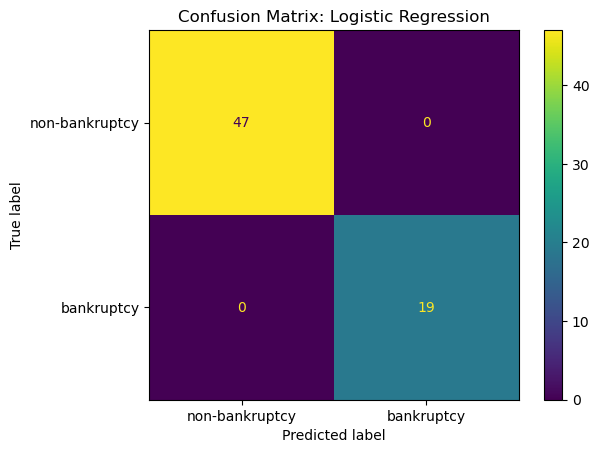

In [44]:
ConfusionMatrixDisplay.from_estimator(lr,x_test,y_test,display_labels=['non-bankruptcy','bankruptcy'])
plt.title('Confusion Matrix: Logistic Regression')
plt.show()

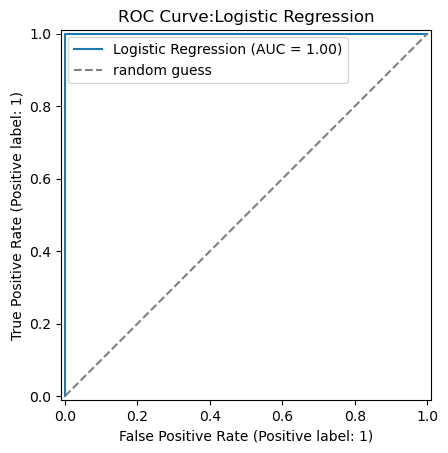

ROC-AUC: 1.0


In [45]:
RocCurveDisplay.from_estimator(lr,x_test,y_test,name='Logistic Regression')
plt.plot([0,1],[0,1],'--',color='grey',label='random guess')
plt.title('ROC Curve:Logistic Regression')
plt.legend()
plt.show()

print('ROC-AUC:',round(roc_auc_score(y_test,lr.predict_proba(x_test)[:,1]),3))

In [46]:
#tesing logistic regression with an ip
ip=[1,0.5,0,0,0,1]
new=pd.DataFrame([ip],columns=features.columns)
p=lr.predict_proba(new)[0][1]
print(f'{p*100:.2f}%')

97.08%


**KNN**

In [47]:
from sklearn.neighbors import KNeighborsClassifier

In [48]:
knn=KNeighborsClassifier(n_neighbors=5)
cv_pred=cross_val_predict(knn,x_train,y_train,cv=cv,groups=groups_train)
print(classification_report(y_train,cv_pred,target_names=labels))

                precision    recall  f1-score   support

non-bankruptcy       0.99      0.99      0.99        96
    bankruptcy       0.99      0.99      0.99        88

      accuracy                           0.99       184
     macro avg       0.99      0.99      0.99       184
  weighted avg       0.99      0.99      0.99       184



In [49]:
knn.fit(x_train,y_train)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [50]:
pred_knn=knn.predict(x_test)
proba_knn=knn.predict_proba(x_test)[:,1]
print(classification_report(y_test,pred_knn,target_names=labels))

                precision    recall  f1-score   support

non-bankruptcy       1.00      0.96      0.98        47
    bankruptcy       0.90      1.00      0.95        19

      accuracy                           0.97        66
     macro avg       0.95      0.98      0.96        66
  weighted avg       0.97      0.97      0.97        66



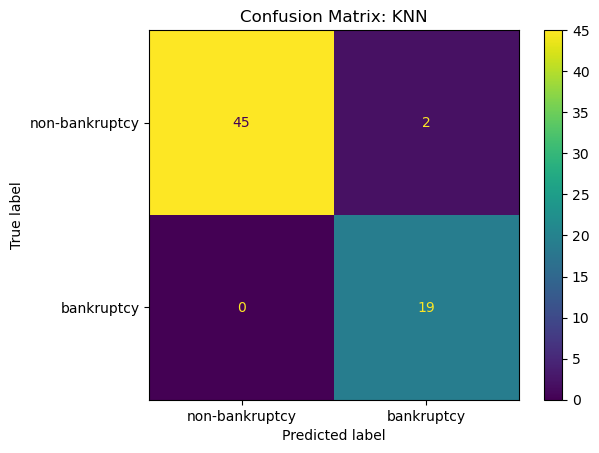

In [51]:
ConfusionMatrixDisplay.from_estimator(knn,x_test,y_test,display_labels=['non-bankruptcy','bankruptcy'])
plt.title('Confusion Matrix: KNN')
plt.show()

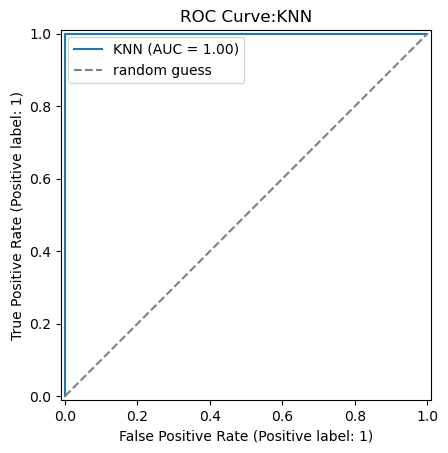

ROC-AUC: 1.0


In [52]:
RocCurveDisplay.from_estimator(knn,x_test,y_test,name='KNN')
plt.plot([0,1],[0,1],'--',color='grey',label='random guess')
plt.title('ROC Curve:KNN')
plt.legend()
plt.show()

print('ROC-AUC:',round(roc_auc_score(y_test,knn.predict_proba(x_test)[:,1]),3))

In [53]:
#tesing KNN with an ip
ip=[1,0.5,0,0,0,1]
new=pd.DataFrame([ip],columns=features.columns)
p=knn.predict_proba(new)[0][1]
print(f'{p*100:.2f}%')

100.00%


**SVC**

In [54]:
from sklearn.svm import SVC

In [55]:
svm=SVC(probability=True,random_state=100)
cv_pred=cross_val_predict(svm,x_train,y_train,cv=cv,groups=groups_train)
print(classification_report(y_train,cv_pred,target_names=labels))

                precision    recall  f1-score   support

non-bankruptcy       0.99      1.00      0.99        96
    bankruptcy       1.00      0.99      0.99        88

      accuracy                           0.99       184
     macro avg       0.99      0.99      0.99       184
  weighted avg       0.99      0.99      0.99       184



In [56]:
svm.fit(x_train,y_train)
pred_svm=svm.predict(x_test)
proba_svm=svm.predict_proba(x_test)[:,1]

In [57]:
print(classification_report(y_test,pred_svm,target_names=labels))

                precision    recall  f1-score   support

non-bankruptcy       1.00      1.00      1.00        47
    bankruptcy       1.00      1.00      1.00        19

      accuracy                           1.00        66
     macro avg       1.00      1.00      1.00        66
  weighted avg       1.00      1.00      1.00        66



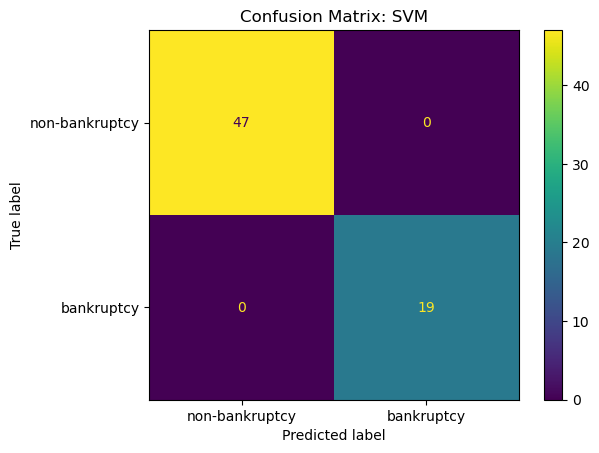

In [58]:
ConfusionMatrixDisplay.from_estimator(svm,x_test,y_test,display_labels=['non-bankruptcy','bankruptcy'])
plt.title('Confusion Matrix: SVM')
plt.show()

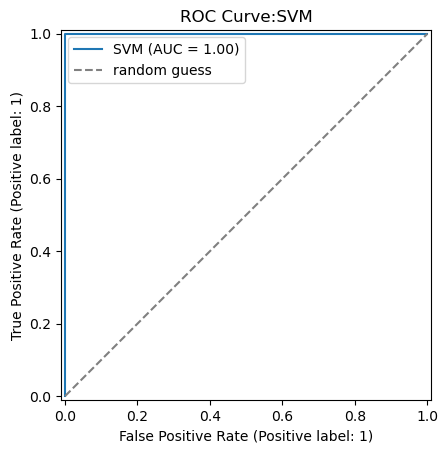

ROC-AUC: 1.0


In [59]:
RocCurveDisplay.from_estimator(svm,x_test,y_test,name='SVM')
plt.plot([0,1],[0,1],'--',color='grey',label='random guess')
plt.title('ROC Curve:SVM')
plt.legend()
plt.show()

print('ROC-AUC:',round(roc_auc_score(y_test,svm.predict_proba(x_test)[:,1]),3))

In [60]:
#tesing SVM with an ip
ip=[1,0.5,0,0,0,1]
new=pd.DataFrame([ip],columns=features.columns)
p=svm.predict_proba(new)[0][1]
print(f'{p*100:.2f}%')

99.57%


**Decision Tree**

In [61]:
from sklearn.tree import DecisionTreeClassifier

In [62]:
dt=DecisionTreeClassifier(max_depth=3,random_state=42)
cv_pred=cross_val_predict(dt,x_train,y_train,cv=cv,groups=groups_train)
print(classification_report(y_train,cv_pred,target_names=labels))

                precision    recall  f1-score   support

non-bankruptcy       0.96      1.00      0.98        96
    bankruptcy       1.00      0.95      0.98        88

      accuracy                           0.98       184
     macro avg       0.98      0.98      0.98       184
  weighted avg       0.98      0.98      0.98       184



In [63]:
dt.fit(x_train,y_train)
pred_dt=dt.predict(x_test)
proba_dt=dt.predict_proba(x_test)[:,1]

In [64]:
print(classification_report(y_test,pred_dt,target_names=labels))

                precision    recall  f1-score   support

non-bankruptcy       1.00      0.91      0.96        47
    bankruptcy       0.83      1.00      0.90        19

      accuracy                           0.94        66
     macro avg       0.91      0.96      0.93        66
  weighted avg       0.95      0.94      0.94        66



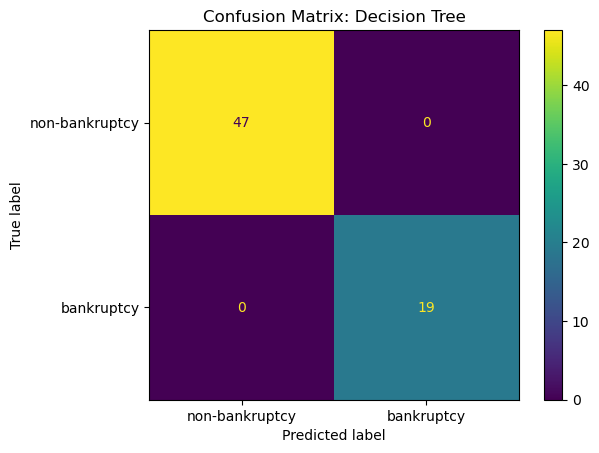

In [65]:
ConfusionMatrixDisplay.from_estimator(svm,x_test,y_test,display_labels=['non-bankruptcy','bankruptcy'])
plt.title('Confusion Matrix: Decision Tree')
plt.show()

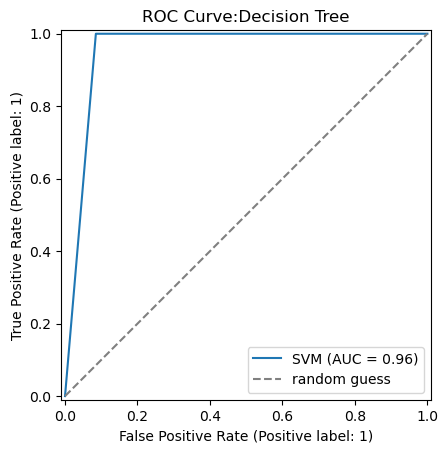

ROC-AUC: 0.957


In [66]:
RocCurveDisplay.from_estimator(dt,x_test,y_test,name='SVM')
plt.plot([0,1],[0,1],'--',color='grey',label='random guess')
plt.title('ROC Curve:Decision Tree')
plt.legend()
plt.show()

print('ROC-AUC:',round(roc_auc_score(y_test,dt.predict_proba(x_test)[:,1]),3))

In [67]:
from sklearn.tree import plot_tree,export_text

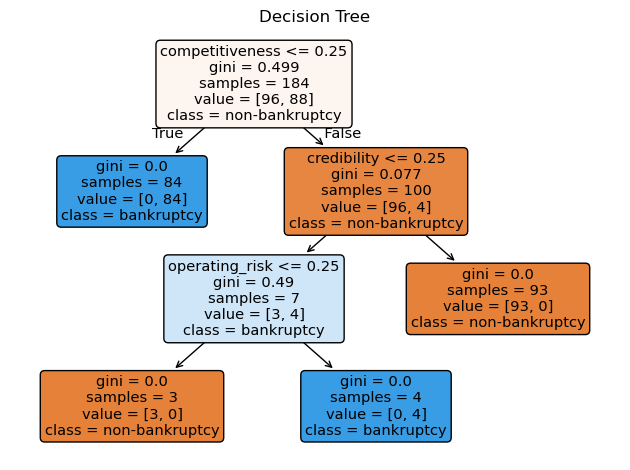

In [68]:
plot_tree(dt,feature_names=features.columns,class_names=labels,filled=True,rounded=True)
plt.title('Decision Tree')
plt.tight_layout()
plt.show()

In [69]:
#tesing Decision Tree with an ip
ip=[1,0.5,0,0,0,1]
new=pd.DataFrame([ip],columns=features.columns)
p=dt.predict_proba(new)[0][1]
print(f'{p*100:.2f}%')

100.00%


**Random Forest**

In [70]:
from sklearn.ensemble import RandomForestClassifier

In [71]:
rf=RandomForestClassifier(max_depth=4,random_state=42)

In [72]:
cv_pred=cross_val_predict(rf,x_train,y_train,cv=cv,groups=groups_train)
print(classification_report(y_train,cv_pred,target_names=labels))

                precision    recall  f1-score   support

non-bankruptcy       0.96      1.00      0.98        96
    bankruptcy       1.00      0.95      0.98        88

      accuracy                           0.98       184
     macro avg       0.98      0.98      0.98       184
  weighted avg       0.98      0.98      0.98       184



In [73]:
rf.fit(x_train,y_train)
pred_rf=rf.predict(x_test)
proba_rf=rf.predict_proba(x_test)[:,1]

In [74]:
print(classification_report(y_test,pred_rf,target_names=labels))

                precision    recall  f1-score   support

non-bankruptcy       1.00      1.00      1.00        47
    bankruptcy       1.00      1.00      1.00        19

      accuracy                           1.00        66
     macro avg       1.00      1.00      1.00        66
  weighted avg       1.00      1.00      1.00        66



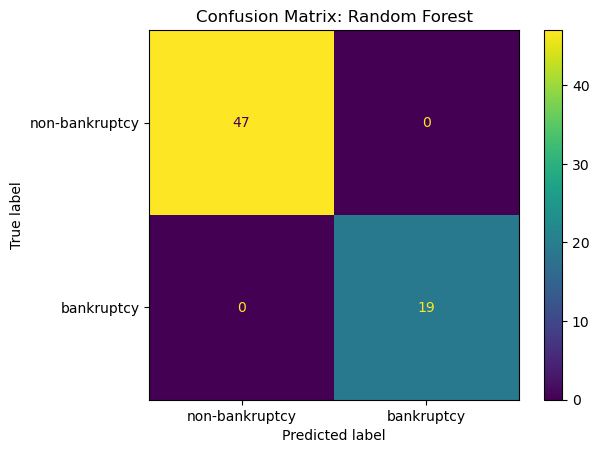

In [75]:
ConfusionMatrixDisplay.from_estimator(rf,x_test,y_test,display_labels=['non-bankruptcy','bankruptcy'])
plt.title('Confusion Matrix: Random Forest')
plt.show()

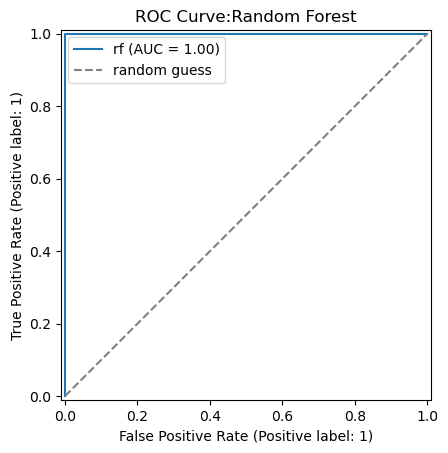

ROC-AUC: 1.0


In [76]:
RocCurveDisplay.from_estimator(rf,x_test,y_test,name='rf')
plt.plot([0,1],[0,1],'--',color='grey',label='random guess')
plt.title('ROC Curve:Random Forest')
plt.legend()
plt.show()

print('ROC-AUC:',round(roc_auc_score(y_test,rf.predict_proba(x_test)[:,1]),3))

In [77]:
#tesing Random Forest with an ip
ip=[1,0.5,0,0,0,1]
new=pd.DataFrame([ip],columns=features.columns)
p=rf.predict_proba(new)[0][1]
print(f'{p*100:.2f}%')

99.95%


In [78]:
import joblib

# Save the selected model
joblib.dump(lr, 'logistic_regression_model.pkl')

# Save feature names
joblib.dump(
    list(features.columns),
    'feature_names.pkl'
)

print("Model saved successfully!")

Model saved successfully!
